In [1]:
import csv
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D
from matplotlib.ticker import FixedLocator, FuncFormatter, NullLocator
from scipy.optimize import brentq
from scipy.special import erf, gammaln, kve, ndtri
from scipy.stats import chi2

ELL = 1.0
EPSILON = 0.1
INPUT_COVERAGE = 0.99
JOINT_CONFIDENCE = 0.95
FIELD_CONFIDENCE = JOINT_CONFIDENCE / INPUT_COVERAGE

C3 = 2.0 * np.sqrt(120.0)
SIGMA_FACTOR = np.sqrt(2.0) * C3 / 3.0

FIG4_DIMENSIONS = (2, 16, 64)
NORMALIZED_RADII = np.geomspace(0.035, 0.35, 1201)

DIMENSION_TICKS = (2, 4, 8, 16, 32, 64, 128, 256)
FIG5_DIMENSIONS = np.arange(DIMENSION_TICKS[0], DIMENSION_TICKS[-1] + 1)

FIG_DIR = Path("figs")
FIG_DIR.mkdir(parents=True, exist_ok=True)

print(f"Figure 4: {NORMALIZED_RADII.size} radii, D = {FIG4_DIMENSIONS}")
print(f"Figure 5: D = {FIG5_DIMENSIONS[0]} to {FIG5_DIMENSIONS[-1]}")
print(f"Required field confidence for Figure 5: {FIELD_CONFIDENCE:.6f}")

Figure 4: 1201 radii, D = (2, 16, 64)
Figure 5: D = 2 to 256
Required field confidence for Figure 5: 0.959596


In [3]:
KERNELS = (
    ("squared_exponential", "se", None),
    ("rational_quadratic", "rq", 1.0),
    ("matern_7_2", "matern", 3.5),
    ("matern_9_2", "matern", 4.5),
)


def kernel_derivative(s, order, family, shape=None):
    """Evaluate h, h', or h'' with respect to squared distance s."""
    s = np.asarray(s, dtype=float)
    if order not in (0, 1, 2) or np.any(s < 0):
        raise ValueError("Use order 0, 1 or 2 and nonnegative squared distances.")

    if family == "se":
        return (-ELL**-2)**order * np.exp(-s / ELL**2)

    if family == "rq":
        a = shape
        moment = np.exp(gammaln(a + order) - gammaln(a)) / (a * ELL**2)**order
        return (-1.0)**order * moment * np.exp(
            -(a + order) * np.log1p(s / (a * ELL**2))
        )

    if family == "matern":
        nu = shape
        b = (nu - 1.0) / ELL**2
        q = nu - order
        t = b * s
        safe_t = np.where(t > 0.0, t, 1.0)
        z = 2.0 * np.sqrt(safe_t)
        log_factor = (
            np.log(2.0) + 0.5 * q * np.log(safe_t)
            - gammaln(q) + np.log(kve(q, z)) - z
        )
        factor = np.where(t > 0.0, np.exp(np.minimum(log_factor, 0.0)), 1.0)
        moment = b**order * np.exp(gammaln(q) - gammaln(nu))
        return (-1.0)**order * moment * factor

    raise ValueError(f"Unknown covariance family: {family}")


def third_moment(family, shape=None):
    """Return gamma_3 = -h'''(0+) for the normalized profile."""
    if family == "se":
        return ELL**-6
    if family == "rq":
        a = shape
        return (a + 1.0) * (a + 2.0) / (a**2 * ELL**6)
    if family == "matern" and shape > 3:
        nu = shape
        return (nu - 1.0)**2 / ((nu - 2.0) * (nu - 3.0) * ELL**6)
    raise ValueError("A finite third moment is required; Matérn needs nu > 3.")


def pointwise_variance_envelope(radius, family, shape=None):
    """Evaluate the original pointwise variance envelope V_h(R)."""
    radius = np.asarray(radius, dtype=float)
    if np.any(radius < 0):
        raise ValueError("R must be nonnegative.")

    t = 2.0 * radius**2
    h1 = kernel_derivative(0.0, 1, family, shape)
    h2 = kernel_derivative(0.0, 2, family, shape)

    return (
        2.0 * (1.0 - kernel_derivative(8.0 * radius**2, 0, family, shape))
        + 16.0 * radius**2 * np.maximum(
            -h1 + 2.0 * kernel_derivative(t, 1, family, shape), 0.0
        )
        + 16.0 * radius**4 * np.maximum(
            h2 - 2.0 * kernel_derivative(t, 2, family, shape), 0.0
        )
    )


for identifier, family, shape in KERNELS:
    np.testing.assert_allclose(kernel_derivative(0.0, 0, family, shape), 1.0)
    np.testing.assert_allclose(kernel_derivative(0.0, 1, family, shape), -ELL**-2)
    print(f"{identifier:<22} gamma3 = {third_moment(family, shape):.6f}")

squared_exponential    gamma3 = 1.000000
rational_quadratic     gamma3 = 6.000000
matern_7_2             gamma3 = 8.333333
matern_9_2             gamma3 = 3.266667


In [5]:
def chi_mean(dimension):
    """Return E||g|| for g ~ N(0, I_D)."""
    dimension = np.asarray(dimension, dtype=float)
    if np.any(dimension < 1) or np.any(dimension != np.floor(dimension)):
        raise ValueError("Dimensions must be positive integers.")
    return np.sqrt(2.0) * np.exp(
        gammaln((dimension + 1.0) / 2.0) - gammaln(dimension / 2.0)
    )


def input_chi2_quantile(dimension):
    """Choose q_D so the two independent inputs are both in the balls."""
    return chi2.ppf(np.sqrt(INPUT_COVERAGE), dimension)


def input_variance(radius, dimension):
    """Return the input coordinate variance R^2 / q_D."""
    return np.asarray(radius, dtype=float)**2 / input_chi2_quantile(dimension)


def field_probability_bounds(radius, dimension, family, shape=None):
    """Return field-only bounds for absolute error at tolerance EPSILON."""
    radius = np.asarray(radius, dtype=float)
    if np.any(radius <= 0.0):
        raise ValueError("R must be positive.")

    variance = pointwise_variance_envelope(radius, family, shape)
    envelope_sd = np.sqrt(np.maximum(variance, 0.0))
    sqrt_gamma3 = np.sqrt(third_moment(family, shape))
    cubic_sd = SIGMA_FACTOR * sqrt_gamma3 * radius**3
    refined_sd = np.minimum(envelope_sd, cubic_sd)

    mean_bound = 2.0 * C3 * chi_mean(dimension) * sqrt_gamma3 * radius**3
    gap = np.maximum(EPSILON - mean_bound, 0.0)

    pointwise_original = erf(EPSILON / (np.sqrt(2.0) * envelope_sd))
    pointwise_refined = erf(EPSILON / (np.sqrt(2.0) * refined_sd))
    simultaneous = -np.expm1(-0.5 * (gap / cubic_sd)**2)

    return pointwise_original, pointwise_refined, simultaneous


def joint_probability_bounds(radius, dimension, family, shape=None):
    """Return bounds on success probability over both the field and inputs."""
    return tuple(
        INPUT_COVERAGE * bound
        for bound in field_probability_bounds(radius, dimension, family, shape)
    )


FIG4_RADII = ELL * NORMALIZED_RADII
FIG4_BOUNDS = {
    (dimension, identifier): joint_probability_bounds(
        FIG4_RADII, dimension, family, shape
    )
    for dimension in FIG4_DIMENSIONS
    for identifier, family, shape in KERNELS
}

print(f"Figure 4 data ready: {len(FIG4_BOUNDS)} panels, "
      f"{FIG4_RADII.size} radii per panel.")

Figure 4 data ready: 12 panels, 1201 radii per panel.


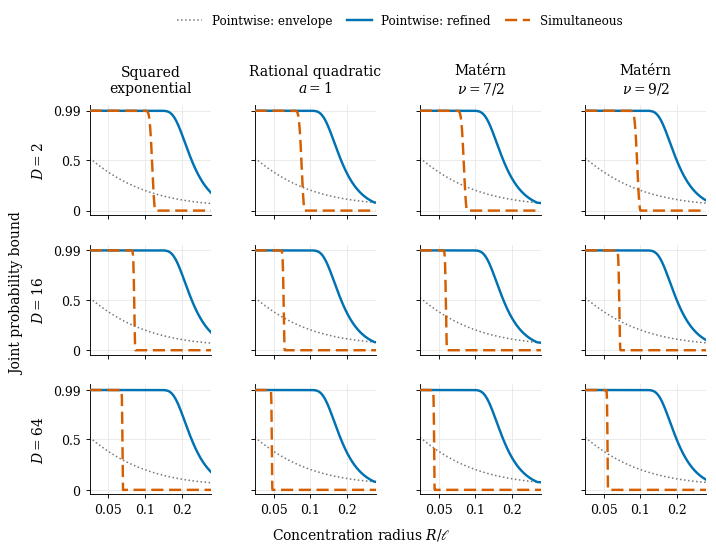

Saved: figs/probability_bounds_combined.pdf
Saved: figs/probability_bounds_combined.png
Saved: figs/probability_bounds_data.csv


In [6]:
FIGURE_STYLE = {
    "font.family": "serif",
    "font.serif": ["DejaVu Serif"],
    "mathtext.fontset": "dejavuserif",
    "font.size": 9,
    "axes.titlesize": 10,
    "axes.labelsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "axes.linewidth": 0.65,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "savefig.facecolor": "white",
}

BLUE, ORANGE, GRAY = "#0072B2", "#D55E00", "#777777"
FIG4_TITLES = {
    "squared_exponential": "Squared\nexponential",
    "rational_quadratic": "Rational quadratic\n" + r"$a=1$",
    "matern_7_2": "Matérn\n" + r"$\nu=7/2$",
    "matern_9_2": "Matérn\n" + r"$\nu=9/2$",
}

figure4_pdf = FIG_DIR / "probability_bounds_combined.pdf"
figure4_png = FIG_DIR / "probability_bounds_combined.png"
figure4_csv = FIG_DIR / "probability_bounds_data.csv"
figure4_rows = []

with plt.rc_context({**FIGURE_STYLE, "legend.fontsize": 8.6}):
    fig4, axes = plt.subplots(
        len(FIG4_DIMENSIONS), len(KERNELS), figsize=(7.05, 5.60),
        sharex=True, sharey=True, squeeze=False
    )
    fig4.subplots_adjust(
        left=0.115, right=0.99, bottom=0.12, top=0.815,
        hspace=0.27, wspace=0.36
    )

    for row, dimension in enumerate(FIG4_DIMENSIONS):
        q_d = input_chi2_quantile(dimension)
        variances = input_variance(FIG4_RADII, dimension)

        for col, (identifier, family, shape) in enumerate(KERNELS):
            ax = axes[row, col]
            original, refined, simultaneous = FIG4_BOUNDS[dimension, identifier]

            ax.plot(NORMALIZED_RADII, original, color=GRAY,
                    lw=1.1, ls=":", zorder=2)
            ax.plot(NORMALIZED_RADII, refined, color=BLUE, lw=1.75, zorder=3)
            ax.plot(NORMALIZED_RADII, simultaneous, color=ORANGE,
                    lw=1.75, ls=(0, (5, 2.3)), zorder=4)

            ax.set_xscale("log")
            ax.set_xlim(NORMALIZED_RADII[0], NORMALIZED_RADII[-1])
            ax.set_ylim(-0.045, 1.045)
            ax.set_yticks([0, 0.5, INPUT_COVERAGE],
                          labels=["0", "0.5", f"{INPUT_COVERAGE:g}"])
            ax.xaxis.set_major_locator(FixedLocator([0.05, 0.1, 0.2]))
            ax.xaxis.set_major_formatter(FuncFormatter(lambda x, pos: f"{x:g}"))
            ax.xaxis.set_minor_locator(NullLocator())
            ax.tick_params(axis="both", length=3, width=0.65)
            ax.grid(True, color="#E6E6E6", linewidth=0.55)

            if row == 0:
                ax.set_title(FIG4_TITLES[identifier], pad=9)
            if col == 0:
                ax.set_ylabel(rf"$D={dimension}$", labelpad=5)

            figure4_rows.extend(
                (family, shape, dimension, EPSILON, ELL, INPUT_COVERAGE,
                 q_d, r, r / ELL, variance, p_original, p_refined, p_sim)
                for r, variance, p_original, p_refined, p_sim in zip(
                    FIG4_RADII, variances, original, refined, simultaneous
                )
            )

    handles = [
        Line2D([], [], color=GRAY, lw=1.1, ls=":", label="Pointwise: envelope"),
        Line2D([], [], color=BLUE, lw=1.75, label="Pointwise: refined"),
        Line2D([], [], color=ORANGE, lw=1.75, ls=(0, (5, 2.3)),
               label="Simultaneous"),
    ]
    fig4.legend(handles=handles, loc="upper center",
                bbox_to_anchor=(0.555, 0.997), ncol=3, frameon=False,
                handlelength=2.1, columnspacing=1.2)
    fig4.text(0.012, 0.48, "Joint probability bound",
              rotation=90, va="center", ha="center", fontsize=10)
    fig4.supxlabel(r"Concentration radius $R/\ell$", y=0.035, fontsize=10)

    fig4.savefig(figure4_pdf, bbox_inches="tight", pad_inches=0.045,
                 metadata={"CreationDate": None})
    fig4.savefig(figure4_png, dpi=220, bbox_inches="tight", pad_inches=0.045)
    plt.show()
    plt.close(fig4)

with figure4_csv.open("w", newline="", encoding="utf-8") as stream:
    writer = csv.writer(stream)
    writer.writerow((
        "family", "shape", "D", "epsilon", "ell", "input_pair_coverage", "q_D",
        "R", "R_over_ell", "input_coordinate_variance", "joint_pointwise_envelope",
        "joint_pointwise_refined", "joint_simultaneous",
    ))
    writer.writerows(figure4_rows)

print(f"Saved: {figure4_pdf}\nSaved: {figure4_png}\nSaved: {figure4_csv}")

In [ ]:
def admissible_radii(dimension, family, shape=None):
    """Invert the three joint probability bounds at JOINT_CONFIDENCE."""
    z = ndtri((1.0 + FIELD_CONFIDENCE) / 2.0)
    target_variance = (EPSILON / z)**2

    upper = ELL
    while pointwise_variance_envelope(upper, family, shape) < target_variance:
        upper *= 2.0

    envelope_radius = brentq(
        lambda r: pointwise_variance_envelope(r, family, shape) - target_variance,
        0.0, upper, xtol=1e-13 * ELL
    )

    sqrt_gamma3 = np.sqrt(third_moment(family, shape))
    cubic_radius = np.cbrt(EPSILON / (z * SIGMA_FACTOR * sqrt_gamma3))

    refined_radius = max(envelope_radius, cubic_radius)

    tail_factor = np.sqrt(-2.0 * np.log1p(-FIELD_CONFIDENCE))
    simultaneous_radius = np.cbrt(
        EPSILON / (
            sqrt_gamma3
            * (2.0 * C3 * chi_mean(dimension) + SIGMA_FACTOR * tail_factor)
        )
    )

    return envelope_radius, refined_radius, simultaneous_radius


FIG5_RADII = {
    identifier: admissible_radii(FIG5_DIMENSIONS, family, shape)
    for identifier, family, shape in KERNELS
}

print(f"Figure 5 data ready: {len(FIG5_RADII)} profiles, "
      f"{FIG5_DIMENSIONS.size} dimensions.")

Figure 5 data ready: 4 profiles, 255 dimensions.


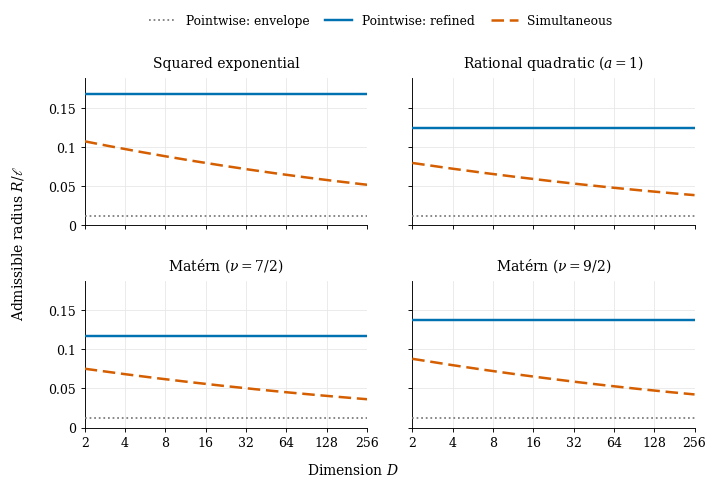

Saved: figs/radius_dimension.pdf
Saved: figs/radius_dimension.png
Saved: figs/radius_dimension_data.csv


In [8]:
FIG5_TITLES = {
    "squared_exponential": "Squared exponential",
    "rational_quadratic": r"Rational quadratic ($a=1$)",
    "matern_7_2": r"Matérn ($\nu=7/2$)",
    "matern_9_2": r"Matérn ($\nu=9/2$)",
}

figure5_pdf = FIG_DIR / "radius_dimension.pdf"
figure5_png = FIG_DIR / "radius_dimension.png"
figure5_csv = FIG_DIR / "radius_dimension_data.csv"
figure5_rows = []

with plt.rc_context({**FIGURE_STYLE, "legend.fontsize": 8.8}):
    fig5, axes = plt.subplots(
        2, 2, figsize=(7.05, 4.85), sharex=True, sharey=True
    )
    fig5.subplots_adjust(
        left=0.12, right=0.985, bottom=0.12, top=0.84,
        hspace=0.38, wspace=0.16
    )

    for ax, (identifier, _, _) in zip(axes.flat, KERNELS):
        envelope, refined, simultaneous = FIG5_RADII[identifier]

        ax.axhline(envelope / ELL, color=GRAY, lw=1.25, ls=":", zorder=3)
        ax.axhline(refined / ELL, color=BLUE, lw=1.75, zorder=3)
        ax.plot(FIG5_DIMENSIONS, simultaneous / ELL, color=ORANGE,
                lw=1.8, ls=(0, (5, 2.3)), zorder=4)

        ax.set_xscale("log", base=2)
        ax.set_xlim(DIMENSION_TICKS[0], DIMENSION_TICKS[-1])
        ax.xaxis.set_major_locator(FixedLocator(DIMENSION_TICKS))
        ax.xaxis.set_major_formatter(FuncFormatter(lambda x, pos: f"{x:g}"))
        ax.xaxis.set_minor_locator(NullLocator())
        ax.set_title(FIG5_TITLES[identifier], pad=8)
        ax.tick_params(axis="both", length=3, width=0.65)
        ax.grid(True, color="#E6E6E6", linewidth=0.55)

        for d in DIMENSION_TICKS:
            index = np.searchsorted(FIG5_DIMENSIONS, d)
            q_d = input_chi2_quantile(d)
            r_sim = simultaneous[index]
            figure5_rows.append((
                identifier, d, EPSILON, JOINT_CONFIDENCE, INPUT_COVERAGE,
                FIELD_CONFIDENCE, q_d, ELL, envelope, refined, r_sim,
                envelope / ELL, refined / ELL, r_sim / ELL,
                envelope**2 / q_d, refined**2 / q_d, r_sim**2 / q_d,
            ))

    largest_radius = max(radii[1] / ELL for radii in FIG5_RADII.values())
    axes[0, 0].set_ylim(0.0, 1.12 * largest_radius)
    axes[0, 0].yaxis.set_major_formatter(FuncFormatter(lambda y, pos: f"{y:g}"))

    handles = [
        Line2D([], [], color=GRAY, lw=1.25, ls=":", label="Pointwise: envelope"),
        Line2D([], [], color=BLUE, lw=1.75, label="Pointwise: refined"),
        Line2D([], [], color=ORANGE, lw=1.8, ls=(0, (5, 2.3)),
               label="Simultaneous"),
    ]
    fig5.legend(handles=handles, loc="upper center",
                bbox_to_anchor=(0.54, 0.995), ncol=3, frameon=False,
                handlelength=2.2, columnspacing=1.3)
    fig5.supylabel(r"Admissible radius $R/\ell$", x=0.014, fontsize=10)
    fig5.supxlabel(r"Dimension $D$", y=0.018, fontsize=10)

    fig5.savefig(figure5_pdf, bbox_inches="tight", pad_inches=0.045,
                 metadata={"CreationDate": None})
    fig5.savefig(figure5_png, dpi=220, bbox_inches="tight", pad_inches=0.045)
    plt.show()
    plt.close(fig5)

with figure5_csv.open("w", newline="", encoding="utf-8") as stream:
    writer = csv.writer(stream)
    writer.writerow((
        "kernel", "D", "epsilon", "joint_confidence", "input_pair_coverage",
        "field_confidence", "q_D", "ell", "R_envelope", "R_refined",
        "R_simultaneous", "R_envelope_over_ell", "R_refined_over_ell",
        "R_simultaneous_over_ell", "lambda_envelope", "lambda_refined",
        "lambda_simultaneous",
    ))
    writer.writerows(figure5_rows)

print(f"Saved: {figure5_pdf}\nSaved: {figure5_png}\nSaved: {figure5_csv}")